# Phân tích khám phá tennis của thành viên B

Notebook bàn giao phần B trên dữ liệu thật giai đoạn 2015–2025. Phần A đã thu thập bản lưu trữ của dữ liệu Jeff Sackmann / Tennis Abstract, ghim commit và checksum. Notebook kiểm tra lại nguồn, chạy module tiền xử lý, rồi khám phá các bảng thống kê dùng chung với C.

Đọc `README.md` để cài môi trường và chạy pipeline trước. Chọn kernel **Python (Tennis A B)**. Không cần tải lại mạng khi dữ liệu raw đã có. Mỗi trận có một dòng winner/loser; ngày nguồn là ngày bắt đầu giải, không phải ngày thực tế của từng trận. Các hình trong notebook là EDA của B; module trực quan hóa và báo cáo tổng hợp vẫn thuộc phần C.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'config/project.json').exists())
sys.path.insert(0, str(ROOT))
from src.data_collection import collect, load_raw
from src.data_validation import load_schema, validate_frame
from src.preprocessing import clean_matches, player_matches
from src.analysis import build_tables, verify_tables

CONFIG = json.loads((ROOT/'config/project.json').read_text())
SCHEMA = load_schema(ROOT/'data/schemas/tennis_schema.json')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)
print('Project:', ROOT)
print('Pinned source commit:', CONFIG['source_commit'])

Project: /Users/mynameisfuong/Documents/KHDL
Pinned source commit: 83733587353df8a41f2fd4f516147d5aa83f5a8d


## Kiểm tra phần A và làm sạch dữ liệu

Đọc raw dưới dạng chuỗi để phát hiện giá trị sai trước khi ép kiểu. Chế độ offline xác minh SHA256 của từng nguồn; không gọi tải dữ liệu mới. Bảng flow cho phép đối soát toàn bộ dòng bị loại hoặc giữ lại.

In [2]:
manifest = collect(ROOT, CONFIG, offline=True)
raw = load_raw(ROOT, CONFIG)
result = clean_matches(raw, SCHEMA, CONFIG)
m = result.matches
assert validate_frame(m, SCHEMA, allow_features=True).empty
assert m.match_id.is_unique
display(pd.DataFrame(result.flow.items(), columns=['metric', 'value']))
display(result.issues.groupby(['severity','field','rule']).size().reset_index(name='n_issues'))
print('Data-source license:', manifest['license'])

,metric,value
0,raw_rows,30616
1,excluded_scope_rows,3042
2,in_scope_rows,27574
3,quarantined_rows,0
4,exact_duplicates_removed,0
5,processed_rows,27574
6,optional_cells_set_missing,122


,severity,field,rule,n_issues
0,warning,l_2ndWon,second_wins_plus_df_gt_second_points,3
1,warning,loser_ht,below_minimum,4
2,warning,minutes,below_minimum,59
3,warning,w_2ndWon,second_wins_gt_second_points,1
4,warning,w_2ndWon,second_wins_plus_df_gt_second_points,4
5,warning,winner_ht,below_minimum,5


Data-source license: CC BY-NC-SA 4.0


## Kiểm tra pipeline trên dữ liệu mẫu

Mẫu chỉ chứa dòng thật và hai bản sao có chủ đích. Mẫu có trường tùy chọn thiếu; không thay thế dữ liệu thật để viết kết luận. Giá trị sai nhân tạo được kiểm tra riêng bằng pytest.

In [3]:
sample = pd.read_csv(ROOT/'data/sample/tennis_sample.csv', dtype='string')
sample_result = clean_matches(sample, SCHEMA, CONFIG)
assert sample_result.flow['exact_duplicates_removed'] == 2
assert validate_frame(sample_result.matches, SCHEMA, allow_features=True).empty
display(pd.DataFrame(sample_result.flow.items(), columns=['metric','value']))

,metric,value
0,raw_rows,127
1,excluded_scope_rows,0
2,in_scope_rows,127
3,quarantined_rows,0
4,exact_duplicates_removed,2
5,processed_rows,125
6,optional_cells_set_missing,0


## Tái tạo bảng thống kê và đối chiếu số liệu bàn giao

Tái tính bảng bằng code trong src/analysis, kiểm tra mẫu số và so sánh với CSV đã xuất. Không chỉnh số thủ công trong notebook.

In [4]:
tables = build_tables(m, raw, SCHEMA)
verify_tables(m, tables)
for name, calculated in tables.items():
    saved = pd.read_csv(ROOT/f'reports/tables/{name}.csv')
    # Round-trip CSV can change nullable dtype, not the numeric values.
    from io import StringIO
    expected = pd.read_csv(StringIO(calculated.to_csv(index=False)))
    pd.testing.assert_frame_equal(saved, expected, check_exact=False, rtol=1e-12, atol=1e-12)
display(tables['season_summary'])
display(tables['score_status'])
print('Verified', len(tables), 'tables against exported CSVs')

,season,n_matches,n_completed,n_tournaments,n_duration,median_minutes,n_ranked_completed,n_upsets,upset_rate
0,2015,2630,2527,66,1315,98.0,2518,782,0.310564
1,2016,2626,2527,66,2520,100.0,2520,814,0.323016
2,2017,2633,2530,67,2501,102.0,2526,874,0.346002
3,2018,2637,2555,67,2544,104.0,2552,930,0.364420
4,2019,2610,2531,66,2527,105.0,2515,975,0.387674
5,2020,1267,1237,32,1237,115.0,1229,449,0.365338
6,2021,2489,2408,61,2406,108.0,2402,895,0.372606
7,2022,2632,2547,68,2428,110.0,2545,908,0.356778
8,2023,2703,2614,65,2614,115.0,2601,952,0.366013
9,2024,2703,2607,65,2484,110.0,2604,942,0.361751


,score_status,n_matches,share
0,completed,26599,0.964641
1,defaulted,7,0.000254
2,retired,789,0.028614
3,walkover,179,0.006492


Verified 14 tables against exported CSVs


## Cơ cấu và xu hướng số trận

Đếm theo mùa của tên file, không dùng năm tourney_date thay cho mùa. Mùa 2020 có số trận thấp hơn; số liệu này tự nó không giải thích nguyên nhân. Tỷ lệ mặt sân tính trên toàn bộ bản ghi trong phạm vi, gồm cả trận chưa hoàn tất.

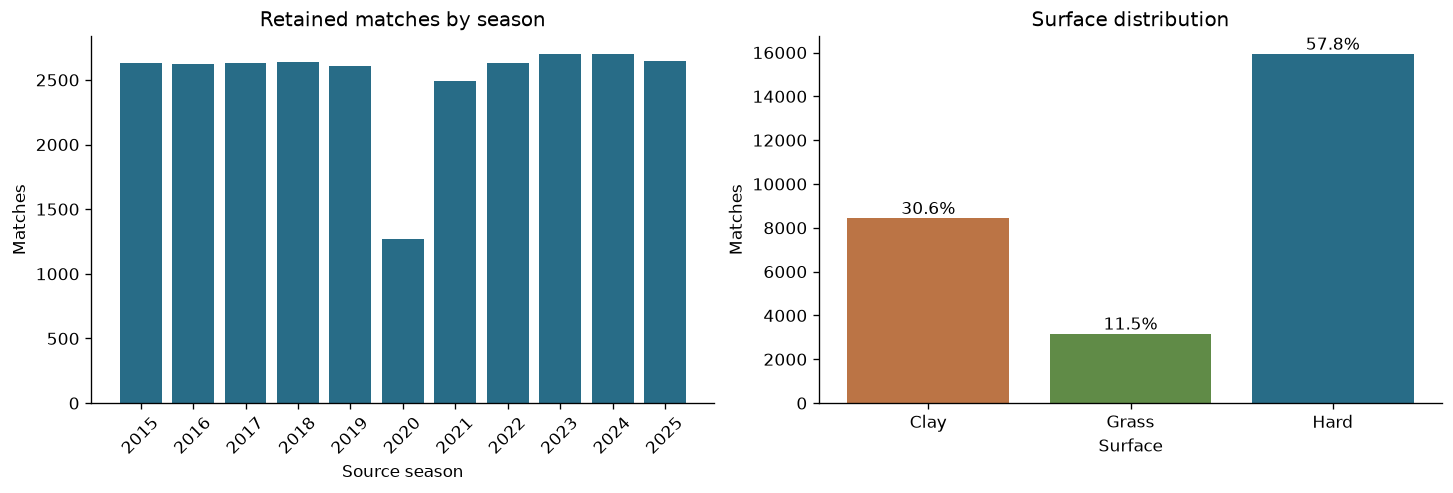

In [5]:
season = tables['season_summary']
surface = tables['surface_summary']
fig, ax = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
ax[0].bar(season.season.astype(str), season.n_matches, color='#286c87')
ax[0].set(title='Retained matches by season', xlabel='Source season', ylabel='Matches')
ax[0].tick_params(axis='x', rotation=45)
ax[1].bar(surface.surface_group, surface.n_matches, color=['#bb7445','#608b47','#286c87'][:len(surface)])
ax[1].set(title='Surface distribution', xlabel='Surface', ylabel='Matches')
for i, row in surface.reset_index(drop=True).iterrows():
    ax[1].text(i, row.n_matches, f'{row.n_matches/len(m):.1%}', ha='center', va='bottom')
plt.show()

## Thiếu dữ liệu và giới hạn so sánh thời gian

Độ phủ thời lượng thay đổi rõ giữa các mùa. Mỗi median chỉ dựa vào số thời lượng có mặt. Các trường stats thiếu có thể có hệ thống theo giải, vì vậy không mặc định dữ liệu thiếu hoàn toàn ngẫu nhiên.

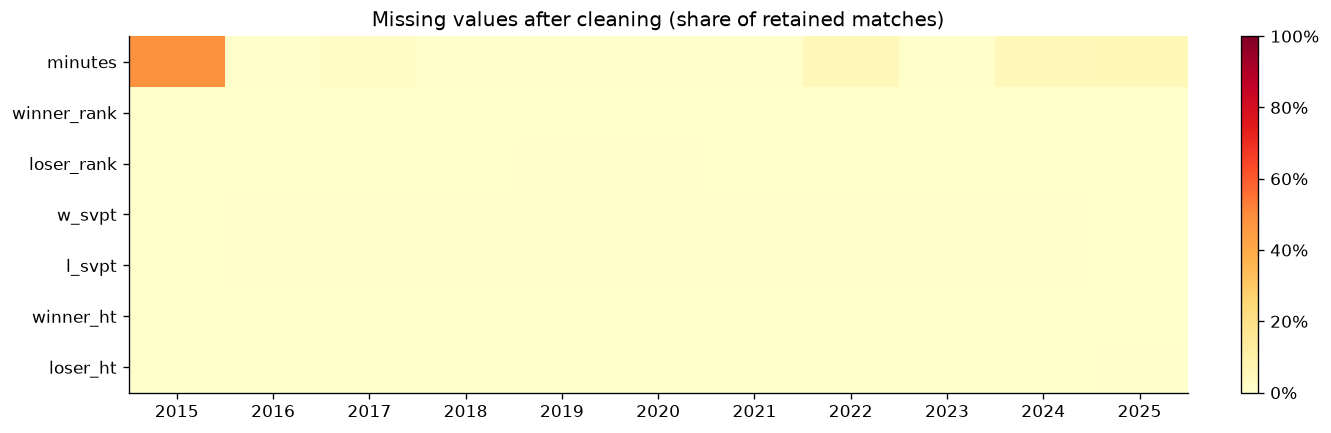

,season,n_completed,n_duration,duration_coverage
0,2015,2527,1315,0.520380
1,2016,2527,2520,0.997230
2,2017,2530,2501,0.988538
3,2018,2555,2544,0.995695
4,2019,2531,2527,0.998420
5,2020,1237,1237,1.000000
6,2021,2408,2406,0.999169
7,2022,2547,2428,0.953278
8,2023,2614,2614,1.000000
9,2024,2607,2484,0.952819


In [6]:
fields = ['minutes','winner_rank','loser_rank','w_svpt','l_svpt','winner_ht','loser_ht']
missing = tables['missingness_by_season']
heat = missing.loc[missing.field.isin(fields)].pivot(index='field',columns='season',values='missing_rate').reindex(fields)
fig, ax = plt.subplots(figsize=(11, 3.5), layout='constrained')
im = ax.imshow(heat.to_numpy(dtype=float), aspect='auto', vmin=0, vmax=1, cmap='YlOrRd')
ax.set_xticks(range(len(heat.columns)), heat.columns.astype(str))
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_title('Missing values after cleaning (share of retained matches)')
fig.colorbar(im, ax=ax, format=PercentFormatter(1))
plt.show()
coverage = season[['season','n_completed','n_duration']].copy()
coverage['duration_coverage'] = coverage.n_duration / coverage.n_completed
display(coverage)

## Phân phối thời lượng và kiểm tra độ nhạy

Chỉ dùng trận completed có thời lượng. Tách thể thức 3 và 5 set. Giữ các thời lượng cực đoan trong thống kê chính, xuất riêng cờ cần kiểm tra và so sánh với bảng độ nhạy. Hình histogram thứ nhất hiển thị toàn miền, để thấy cả các giá trị đáng ngờ.

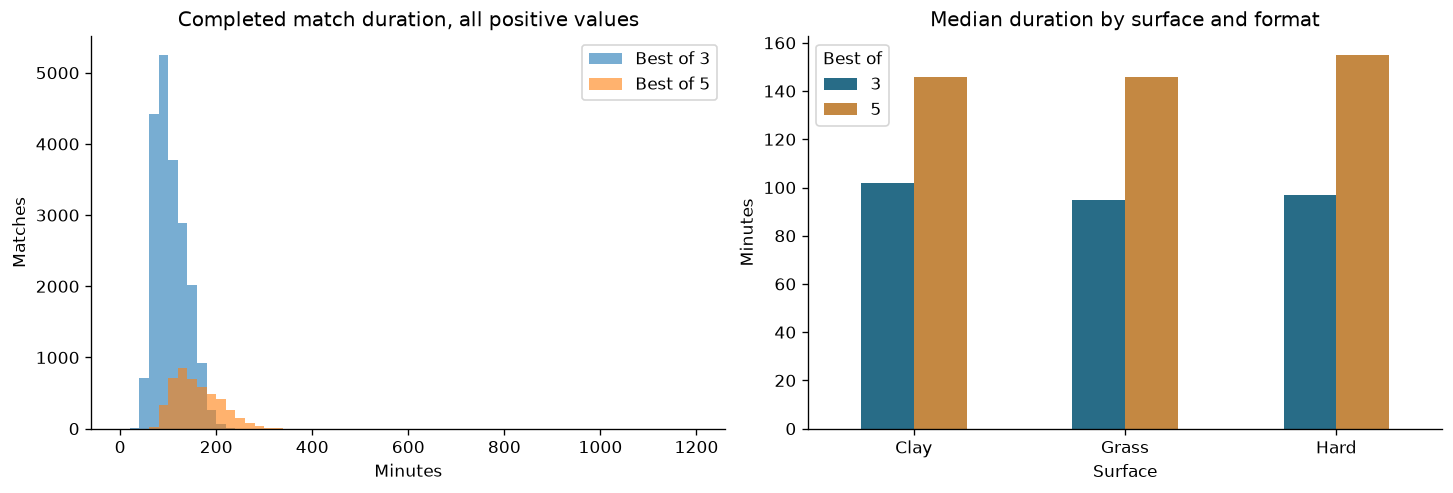

,surface_group,best_of,n_matches,n_duration,missing_duration,mean_minutes,std_minutes,p25_minutes,median_minutes,p75_minutes,p95_minutes,max_minutes
0,Clay,3,6829,6676,153,107.748802,34.750793,81.0,102.0,131.0,168.00,987.0
1,Clay,5,1354,996,358,156.333333,47.740098,121.0,146.0,186.0,248.25,365.0
2,Grass,3,1849,1662,187,99.981348,29.479127,77.0,95.0,121.0,154.00,203.0
3,Grass,5,1229,1106,123,152.931284,45.999555,117.0,146.0,184.0,236.00,396.0
4,Hard,3,12682,11990,692,103.518098,33.073133,79.0,97.0,125.0,162.00,1146.0
5,Hard,5,2656,2544,112,161.922170,47.390259,124.0,155.0,195.0,246.85,345.0


,surface_group,best_of,n_matches,n_duration,missing_duration,mean_minutes,std_minutes,p25_minutes,median_minutes,p75_minutes,p95_minutes,max_minutes
0,Clay,3,6828,6675,153,107.617079,33.044610,81.0,102.0,131.0,168.00,239.0
1,Clay,5,1353,995,358,156.123618,47.302866,121.0,146.0,186.0,248.00,329.0
2,Grass,3,1849,1662,187,99.981348,29.479127,77.0,95.0,121.0,154.00,203.0
3,Grass,5,1228,1105,123,152.711312,45.434685,117.0,146.0,184.0,235.80,315.0
4,Hard,3,12681,11989,692,103.431145,31.674298,79.0,97.0,125.0,162.00,289.0
5,Hard,5,2656,2544,112,161.922170,47.390259,124.0,155.0,195.0,246.85,345.0


,match_id,source_file,source_row,tourney_name,winner_name,loser_name,score,score_status,best_of,minutes
5,2016-M001:294,atp_matches_2016.csv,134,Sydney,Gilles Muller,Jeremy Chardy,7-6(5) 6-3,completed,3,1146
7,2017-0308:297,atp_matches_2017.csv,1259,Munich,Hyeon Chung,Martin Klizan,6-4 3-6 6-2,completed,3,987
17,2018-540:224,atp_matches_2018.csv,1839,Wimbledon,Kevin Anderson,John Isner,7-6(6) 6-7(5) 6-7(9) 6-4 26-24,completed,5,396
22,2020-520:1139,atp_matches_2020.csv,972,Roland Garros,Lorenzo Giustino,Corentin Moutet,0-6 7-6(7) 7-6(3) 2-6 18-16,completed,5,365


In [7]:
completed = m.loc[m.is_completed]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for best_of, g in completed.groupby('best_of'):
    axes[0].hist(g.minutes.dropna().astype(float), bins=np.arange(0, 1201, 20), alpha=.6, label=f'Best of {best_of}')
axes[0].set(title='Completed match duration, all positive values', xlabel='Minutes', ylabel='Matches')
axes[0].legend()
duration = tables['duration_by_surface_format']
pivot = duration.pivot(index='surface_group', columns='best_of', values='median_minutes')
pivot.plot.bar(ax=axes[1], color=['#286c87','#c48842'], rot=0)
axes[1].set(title='Median duration by surface and format', xlabel='Surface', ylabel='Minutes')
axes[1].legend(title='Best of')
plt.show()
display(duration)
display(tables['duration_sensitivity'])
display(tables['duration_review'].loc[tables['duration_review'].score_status.eq('completed')])

## Thứ hạng và tỷ lệ thắng

Upset = người thắng có số rank lớn hơn người thua. Chỉ dùng completed và hai rank khác nhau có mặt. Tỷ lệ thắng theo nhóm rank dùng cả hai phía người chơi. Cùng một người xuất hiện nhiều lần; số liệu không độc lập để dùng kiểm định nhị thức thông thường.

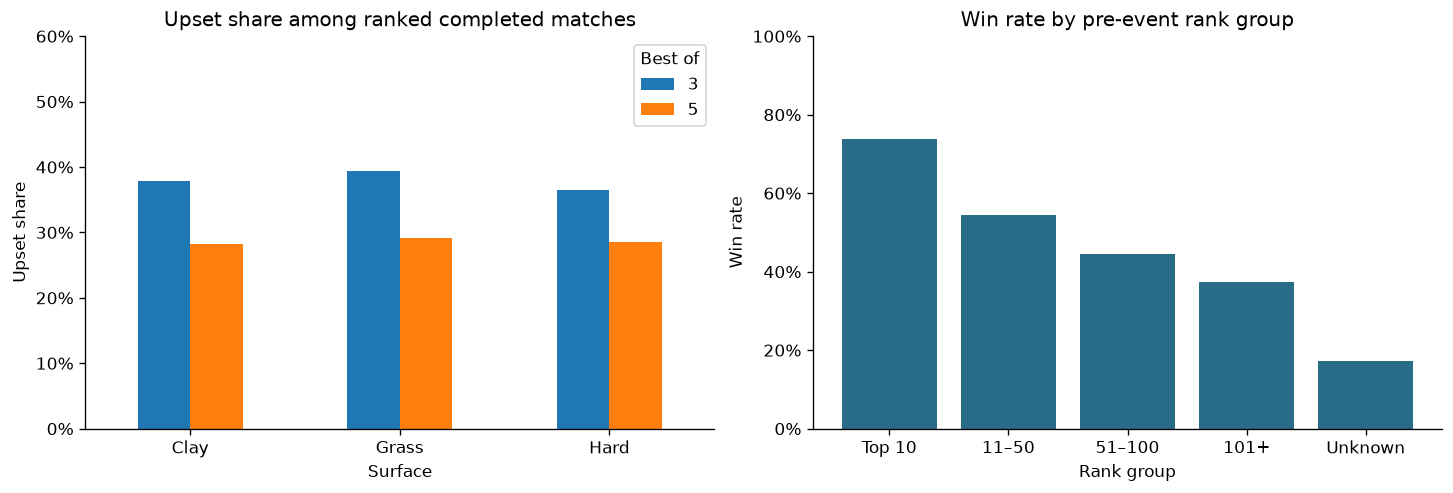

,surface_group,best_of,n_ranked_completed,n_upsets,upset_rate
0,Clay,3,6817,2579,0.378319
1,Clay,5,1352,381,0.281805
2,Grass,3,1838,723,0.393362
3,Grass,5,1229,358,0.291294
4,Hard,3,12645,4612,0.364729
5,Hard,5,2643,755,0.285660


,n_appearances,wins,n_players,losses,win_rate
rank_group,,,,,
Top 10,6086,4486,46,1600,0.737102
11–50,19378,10558,206,8820,0.544845
51–100,16839,7502,322,9337,0.445513
101+,10820,4040,763,6780,0.373383
Unknown,75,13,50,62,0.173333


In [8]:
upsets = tables['upsets_by_surface_format']
rank = tables['rank_group_performance'].set_index('rank_group').reindex(['Top 10','11–50','51–100','101+','Unknown']).dropna(how='all')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
upsets.pivot(index='surface_group',columns='best_of',values='upset_rate').plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Upset share among ranked completed matches', xlabel='Surface', ylabel='Upset share')
axes[0].legend(title='Best of')
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylim(0, .6)
axes[1].bar(rank.index, rank.win_rate, color='#286c87')
axes[1].set(title='Win rate by pre-event rank group', xlabel='Rank group', ylabel='Win rate', ylim=(0,1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
plt.show()
display(upsets[['surface_group','best_of','n_ranked_completed','n_upsets','upset_rate']])
display(rank)

## Giao bóng theo mặt sân

Sử dụng tỷ lệ gộp theo số điểm: tổng ace / tổng điểm giao bóng trên cùng tập lượt có đủ tử và mẫu. Không lấy mean của các tỷ lệ từng trận và không điền stats thiếu. Sự khác biệt chưa điều chỉnh người chơi, thể thức, giải và mùa.

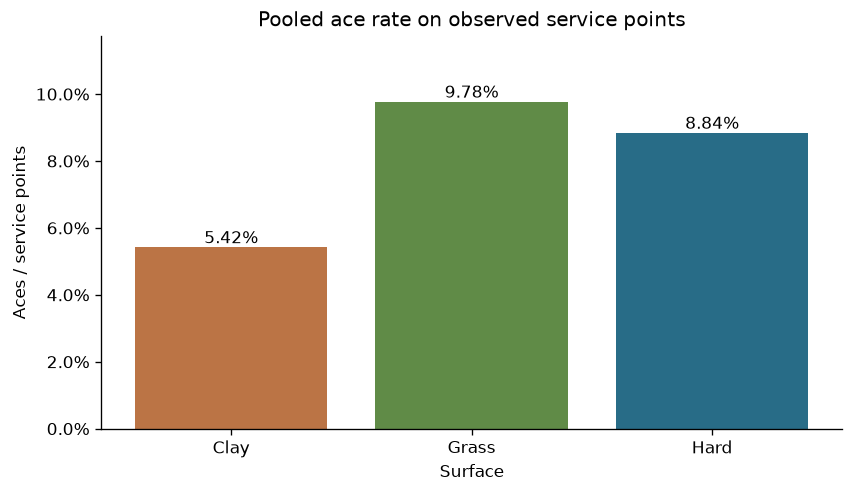

,surface_group,metric,n_appearances,n_possible_appearances,numerator,denominator,rate
0,Clay,ace_rate,16355,16366,71323,1314745,0.054249
1,Clay,double_fault_rate,16355,16366,44542,1314745,0.033879
2,Clay,first_serve_in_rate,16355,16366,818600,1314745,0.622630
3,Clay,first_serve_win_rate,16355,16366,563860,818600,0.688810
4,Clay,second_serve_win_rate,16353,16366,250492,496145,0.504877
5,Clay,break_point_save_rate,15820,16366,72494,120843,0.599902
6,Grass,ace_rate,6154,6156,55157,564258,0.097751
7,Grass,double_fault_rate,6154,6156,21447,564258,0.038009
8,Grass,first_serve_in_rate,6154,6156,354072,564258,0.627500
9,Grass,first_serve_win_rate,6154,6156,262953,354072,0.742654


,field,count,mean,std,min,p25,median,p75,p95,max
0,draw_size,27574.0,65.058533,41.330780,8.0,32.0,32.0,128.0,128.0,128.0
1,winner_ht,27563.0,187.685412,7.077851,168.0,183.0,188.0,193.0,198.0,211.0
2,winner_age,27574.0,27.294089,4.437804,16.7,23.9,27.1,30.3,35.0,42.3
3,loser_ht,27521.0,186.779877,6.955111,163.0,183.0,185.0,191.0,198.0,211.0
4,loser_age,27574.0,27.464078,4.484178,15.0,24.1,27.3,30.5,35.2,42.5
5,best_of,27574.0,3.395663,0.796743,3.0,3.0,3.0,3.0,5.0,5.0
6,minutes,25708.0,113.426288,42.631026,5.0,82.0,106.0,138.0,192.0,1146.0
7,w_ace,27394.0,7.320399,5.751358,0.0,3.0,6.0,10.0,18.0,75.0
8,w_df,27394.0,2.652552,2.305754,0.0,1.0,2.0,4.0,7.0,26.0
9,w_svpt,27394.0,79.493247,29.322543,0.0,58.0,75.0,96.0,135.0,278.0


In [9]:
serve = tables['serve_by_surface']
ace = serve.loc[serve.metric.eq('ace_rate')]
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.bar(ace.surface_group, ace.rate, color=['#bb7445','#608b47','#286c87'][:len(ace)])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='Pooled ace rate on observed service points', xlabel='Surface', ylabel='Aces / service points')
for i, (_, row) in enumerate(ace.iterrows()):
    ax.text(i, row.rate, f'{row.rate:.2%}', ha='center', va='bottom')
ax.set_ylim(0, float(ace.rate.max())*1.2)
plt.show()
display(serve)
display(tables['numeric_summary'])

## Kết luận và bàn giao

Các kết luận định lượng đầy đủ, mẫu số, bảng độ nhạy và hạn chế nằm trong `reports/eda_findings.md`. C nhận 14 bảng CSV và table_contract.json. Dữ liệu đã xử lý nằm ở data/processed. Mã nguồn và kiểm thử là phần chính; notebook dùng lại các module để tránh hai cách tính khác nhau.

Không suy diễn nhân quả từ khác biệt mặt sân. Không dùng winner/loser hoặc stats hậu trận làm đặc trưng dự đoán trước trận. Chưa có mô hình dự đoán trong phần A B.

In [10]:
ranked = m.loc[m.is_completed & m.rank_pair_available]
print(f"Retained matches: {len(m):,}; completed: {int(m.is_completed.sum()):,}")
print(f"Upsets: {int(ranked.is_upset.sum()):,}/{len(ranked):,} = {ranked.is_upset.mean():.2%}")
print(f"Player appearances (completed): {int(tables['rank_group_performance'].n_appearances.sum()):,}")
assert int(tables['rank_group_performance'].n_appearances.sum()) == 2*int(m.is_completed.sum())
print('All notebook accounting checks passed.')

Retained matches: 27,574; completed: 26,599
Upsets: 9,408/26,524 = 35.47%
Player appearances (completed): 53,198
All notebook accounting checks passed.
